Midterm Mini Data Science Project
Customer Segmentation using K-Means Clustering

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df = pd.read_csv('store_customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1000,M,39.0,59.9,58.0
1,1001,M,34.0,48.4,37.0
2,1002,F,40.0,70.5,26.0
3,1003,F,47.0,81.1,30.0
4,1004,F,33.0,42.1,58.0


1. Data Preparation

In [2]:
print("Missing values per column:")
print(df.isna().sum())

for col in ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']:
    df[col] = df[col].fillna(df[col].median())
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

print("\nAfter cleaning:", df.isna().sum().sum(), "missing values remaining")
df.describe().round(2)

Missing values per column:
CustomerID                0
Gender                    3
Age                       6
Annual Income (k$)        4
Spending Score (1-100)    6
dtype: int64

After cleaning: 0 missing values remaining


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,1000.00,1000.00,1000.00,1000.00
mean,1499.50,38.92,57.12,42.67
std,288.82,13.36,28.58,20.04
min,1000.00,18.00,15.00,1.00
25%,1249.75,30.00,35.08,31.75
50%,1499.50,36.00,49.00,47.00
75%,1749.25,44.00,79.32,57.00
max,1999.00,80.00,144.10,92.00


2. Descriptive Statistics

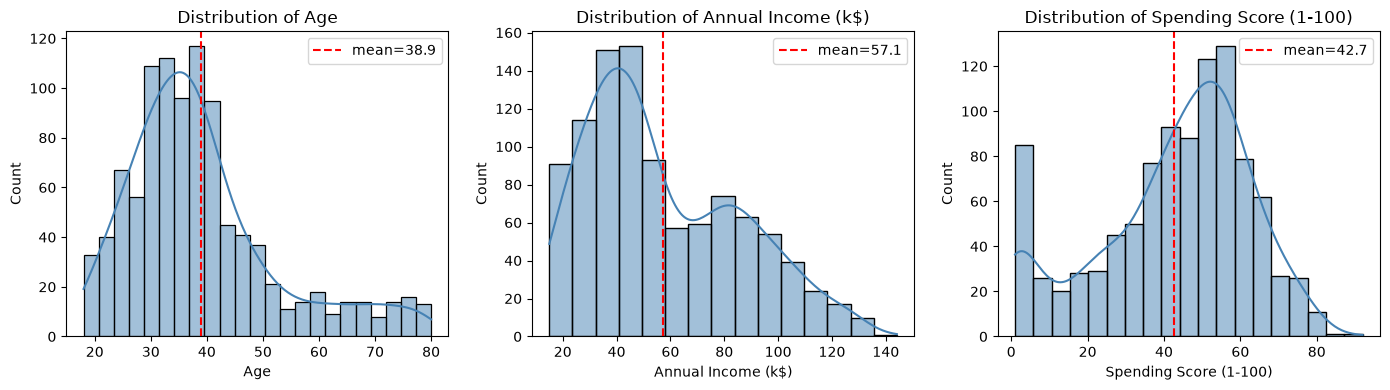

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
for ax, col in zip(axes, features):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue')
    ax.set_title(f'Distribution of {col}')
    ax.axvline(df[col].mean(), color='red', linestyle='--', label=f"mean={df[col].mean():.1f}")
    ax.legend()
plt.tight_layout(); plt.show()

3. Choosing k — The Elbow Method

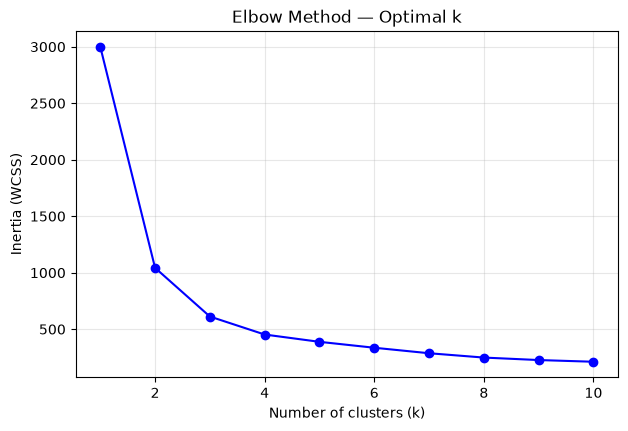

k=4: silhouette score = 0.377
k=5: silhouette score = 0.326
k=6: silhouette score = 0.320


In [4]:
X = df[features]
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(Xs)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4.5))
plt.plot(range(1, 11), inertias, 'bo-')
plt.xlabel('Number of clusters (k)'); plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method — Optimal k'); plt.grid(alpha=0.3); plt.show()

for k in [4, 5, 6]:
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xs)
    print(f"k={k}: silhouette score = {silhouette_score(Xs, labels):.3f}")

4. Running K-Means (k = 5)

In [5]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)
df['Cluster'] = kmeans.fit_predict(Xs)

names = {0: 'Affluent Mature (low spend)', 1: 'Young Low-Income Spenders',
         2: 'Average Everything', 3: 'Wealthy Seniors (minimal spend)',
         4: 'Young Mid-Income Engaged'}
df['Segment'] = df['Cluster'].map(names)

profile = df.groupby('Cluster')[features].mean().round(1)
profile['Size'] = df['Cluster'].value_counts().sort_index()
profile['% Female'] = (df.groupby('Cluster')['Gender']
                       .apply(lambda s: (s == 'F').mean()) * 100).round(1)
profile

,Age,Annual Income (k$),Spending Score (1-100),Size,% Female
Cluster,,,,,
0,47.2,85.6,25.4,160,53.1
1,25.5,26.1,62.1,218,52.8
2,39.1,62.7,41.6,191,52.4
3,67.9,108.7,4.2,116,55.2
4,33.2,41.7,52.8,315,51.1


5. Visualizing the Clusters

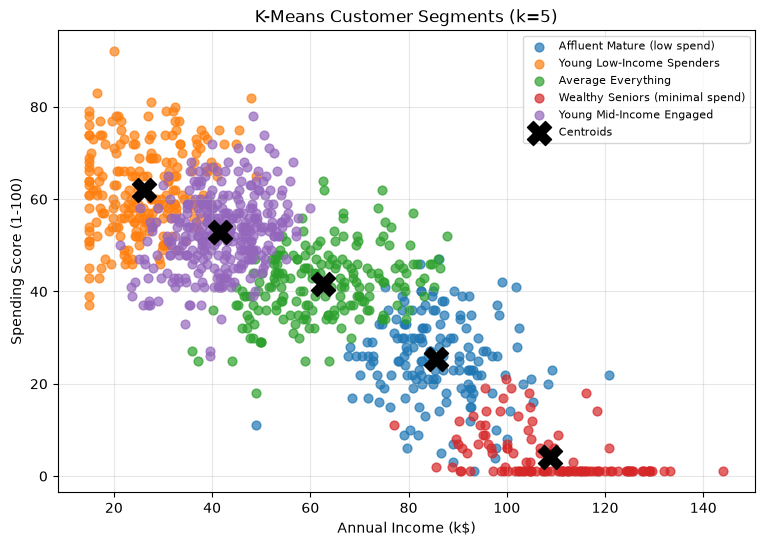

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
palette = sns.color_palette('tab10', 5)
for c in range(5):
    sub = df[df['Cluster'] == c]
    ax.scatter(sub['Annual Income (k$)'], sub['Spending Score (1-100)'],
               s=40, alpha=0.7, color=palette[c], label=names[c])
centers = scaler.inverse_transform(kmeans.cluster_centers_)
ax.scatter(centers[:, 1], centers[:, 2], s=300, marker='X', c='black',
           label='Centroids', zorder=5)
ax.set_xlabel('Annual Income (k$)'); ax.set_ylabel('Spending Score (1-100)')
ax.set_title('K-Means Customer Segments (k=5)')
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()

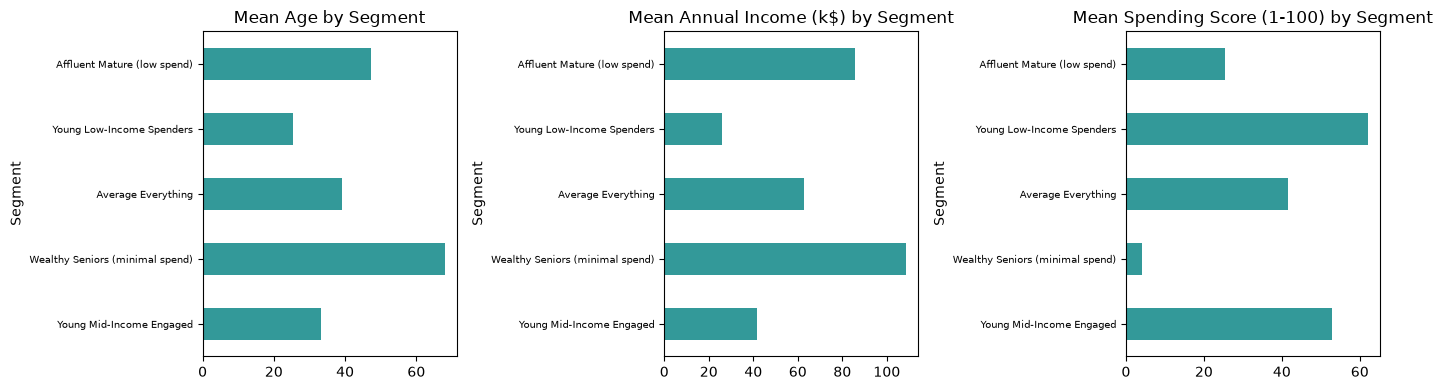

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, features):
    prof = df.groupby('Segment')[col].mean().reindex(list(names.values()))
    prof.plot(kind='barh', ax=ax, color='teal', alpha=0.8)
    ax.set_title(f'Mean {col} by Segment'); ax.invert_yaxis()
    ax.tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.show()